# Evaluación Parcial N°2: Machine Learning
## Inteligencia Musical y Predicción de Popularidad de Canciones (Spotify Tracks)

| Campo | Detalle |
|---|---|
| Integrantes | Catalina Villegas y Javiera Fuenzalida |
| Sección | 002D |
| Asignatura | Machine Learning |
| Docente | Ignacio Meza |

## Metodología CRISP-DM

El proyecto se desarrolla bajo el estándar CRISP-DM (*Cross-Industry Standard Process for Data Mining*):

1. **Comprensión del negocio:** definición de objetivos y KPIs para estimar la popularidad y apoyar decisiones de difusión musical.
2. **Comprensión de los datos:** exploración del dataset Spotify Tracks (114 géneros y atributos de audio), realizada en `EDA.ipynb`.
3. **Preparación de los datos:** partición train/test sin fuga de información, codificación, escalamiento y balanceo del conjunto de entrenamiento.
4. **Modelado:** dos modelos de clasificación (¿es hit?), modelos de regresión (¿cuánta popularidad?) y una técnica no supervisada (PCA y K-Means).
5. **Evaluación:** matriz de confusión, precision, recall, F1, ROC-AUC y PR-AUC para clasificación; RMSE, MAE y R² para regresión; silueta e interpretación de perfiles para K-Means.
6. **Despliegue:** documentación reproducible en este notebook (`.ipynb`), en el informe técnico y en el `README.md`.

## Fuentes de datos y herramientas

* **Fuente de datos:** `Spotify_Tracks_Dataset.csv` (114.000 canciones, 20 variables más un índice). El notebook `EDA.ipynb` genera `Spotify_Tracks_Dataset_Clean.csv` (113.549 filas, 20 columnas), que es el insumo de este notebook.
* **Pandas y NumPy:** manipulación de datos.
* **Matplotlib y Seaborn:** visualizaciones.
* **Scikit-learn:** partición de datos, codificación, escalamiento, RandomForest, Ridge, HistGradientBoosting, PCA, K-Means y métricas.
* **LightGBM y XGBoost:** modelos de gradient boosting.
* **imbalanced-learn:** sobremuestreo SMOTENC.
* **category_encoders:** codificación binaria del género.

## Contexto y problema de negocio

Las plataformas de streaming reciben miles de canciones nuevas cada día. Para discográficas, creadores de contenido y la propia plataforma, anticipar la popularidad de una pista permite priorizar inversión en marketing, armar listas editoriales y aumentar el engagement. Este proyecto busca identificar qué atributos acústicos y metadatos se asocian con la popularidad de una canción en Spotify y construir modelos que la anticipen.

El dataset contiene pistas de 114 géneros, con 1.000 canciones por género aproximadamente, junto con atributos de audio y metadatos.

## Objetivos del proyecto

**Objetivo general:** desarrollar una solución de Machine Learning para predecir la popularidad de canciones en Spotify a partir de sus atributos acústicos y metadatos.

**Objetivos específicos:**

* Aplicar el proceso completo de ciencia de datos bajo CRISP-DM.
* Preparar los datos evitando fuga de información entre entrenamiento y prueba.
* Comparar al menos dos modelos supervisados de clasificación (hit / no hit) y modelos de regresión (popularidad).
* Descubrir perfiles sonoros de canciones mediante PCA y K-Means, e interpretarlos para el negocio.
* Interpretar las métricas y traducirlas en recomendaciones.

## KPIs del negocio

| KPI | Definición |
|---|---|
| Tasa global de hits | Porcentaje del catálogo con `popularity >= 70`. |
| Popularidad promedio por género | Géneros con mayor atractivo comercial. |
| Índice de afinidad sonora | Correlación entre atributos acústicos y popularidad. |
| Duración óptima | Intervalo de duración (minutos) con mayor popularidad. |
| Recall de Hit | Proporción de hits reales que el modelo logra detectar. |
| Precision de Hit | Proporción de canciones marcadas como hit que realmente lo son. |
| RMSE y MAE de popularidad | Error promedio de la predicción, en puntos de popularidad. |

## Preparación de los datos

In [1]:
%pip install -q -U category_encoders imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 4.8 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import category_encoders as ce
from pathlib import Path

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             average_precision_score, silhouette_score, mean_squared_error,
                             mean_absolute_error, r2_score)
from imblearn.over_sampling import SMOTENC
from lightgbm import LGBMClassifier
from xgboost import XGBRegressor

### Carga de datos

El notebook funciona en el repositorio local (`notebooks/`, con los datos en `../data`) y en Google Colab (con el CSV subido a la sesión). Las rutas se detectan automáticamente.

In [3]:
ARCHIVO = 'Spotify_Tracks_Dataset_Clean.csv'

if Path('../data', ARCHIVO).exists():
    RUTA_DATOS, RUTA_IMAGENES = Path('../data', ARCHIVO), Path('../images')
elif Path('data', ARCHIVO).exists():
    RUTA_DATOS, RUTA_IMAGENES = Path('data', ARCHIVO), Path('images')
else:
    RUTA_DATOS, RUTA_IMAGENES = Path(ARCHIVO), Path('images')

RUTA_IMAGENES.mkdir(exist_ok=True)

In [4]:
df = pd.read_csv(RUTA_DATOS)
print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas')
display(df.head())
df.info()

Dataset cargado: 113549 filas x 20 columnas


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4.0,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4.0,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4.0,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.0,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4.0,acoustic


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113549 entries, 0 to 113548
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          113549 non-null  object 
 1   artists           113549 non-null  object 
 2   album_name        113549 non-null  object 
 3   track_name        113549 non-null  object 
 4   popularity        113549 non-null  int64  
 5   duration_ms       113549 non-null  int64  
 6   explicit          113549 non-null  bool   
 7   danceability      113549 non-null  float64
 8   energy            113549 non-null  float64
 9   key               113549 non-null  int64  
 10  loudness          113549 non-null  float64
 11  mode              113549 non-null  int64  
 12  speechiness       113549 non-null  float64
 13  acousticness      113549 non-null  float64
 14  instrumentalness  113549 non-null  float64
 15  liveness          113549 non-null  float64
 16  valence           11

In [5]:
tasa_hit = (df['popularity'] >= 70).mean()
print(f"Géneros: {df['track_genre'].nunique()}")
print(f"Artistas distintos: {df['artists'].nunique()}")
print(f"Filas con track_id repetido: {df['track_id'].duplicated().sum()}")
print(f"Canciones con popularity = 0: {(df['popularity'] == 0).sum()} ({(df['popularity'] == 0).mean():.1%})")
print(f"Tasa global de hits (popularity >= 70): {tasa_hit:.2%}")

Géneros: 114
Artistas distintos: 31437
Filas con track_id repetido: 23809
Canciones con popularity = 0: 15843 (14.0%)
Tasa global de hits (popularity >= 70): 4.82%


### Transformaciones previas a la partición

* `duration_min`: la duración en milisegundos se expresa en minutos para facilitar la lectura.
* `is_hit`: variable objetivo binaria. Una canción es hit si `popularity >= 70`.
* `explicit` se convierte a entero.
* `log1p` se aplica a `speechiness`, `acousticness`, `instrumentalness`, `liveness` y `duration_min`, que son muy asimétricas. Esta transformación no aprende nada de los datos, por lo que puede aplicarse antes de dividir.
* `track_id` se conserva solo para agrupar la partición. Se eliminan `album_name`, `track_name` y `duration_ms`: los dos primeros son texto libre de alta cardinalidad sin valor predictivo directo y el tercero duplica a `duration_min`.

In [6]:
UMBRAL_HIT = 70
df['duration_min'] = df['duration_ms'] / 60000
df['is_hit'] = (df['popularity'] >= UMBRAL_HIT).astype(int)
df['explicit'] = df['explicit'].astype(int)

grupos = df['track_id']
df = df.drop(columns=['track_id', 'album_name', 'track_name', 'duration_ms'])

variables_sesgadas = ['speechiness', 'acousticness', 'instrumentalness', 'liveness', 'duration_min']
for col in variables_sesgadas:
    df[col] = np.log1p(df[col])

COLS_ESCALAR = ['danceability', 'energy', 'loudness', 'tempo',
                'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'duration_min']

### Partición train/test

Se reserva el 20 % de los datos para prueba con `StratifiedGroupKFold`:

* **Agrupada por `track_id`:** una misma canción aparece en varios géneros, por lo que una partición aleatoria deja la misma canción en train y en test y entrega métricas infladas.
* **Estratificada por género:** el conjunto de prueba contiene los 114 géneros.

El conjunto de prueba no se balancea ni se modifica, de modo que no contiene datos sintéticos.

In [7]:
X = df.drop(columns=['popularity', 'is_hit'])
y_hit = df['is_hit']
y_pop = df['popularity']

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_train, idx_test = next(splitter.split(X, df['track_genre'], groups=grupos))

X_train_raw, X_test_raw = X.iloc[idx_train], X.iloc[idx_test]
y_hit_train, y_hit_test = y_hit.iloc[idx_train], y_hit.iloc[idx_test]
y_pop_train, y_pop_test = y_pop.iloc[idx_train], y_pop.iloc[idx_test]

print(f'Train: {len(idx_train)} filas | Test: {len(idx_test)} filas')
print(f"Canciones de test presentes en train: {grupos.iloc[idx_test].isin(grupos.iloc[idx_train]).mean():.0%}")
print(f"Géneros en test: {X_test_raw['track_genre'].nunique()} de {df['track_genre'].nunique()}")
print(f'Tasa de hits en train: {y_hit_train.mean():.2%} | en test: {y_hit_test.mean():.2%}')
print(f"Artistas de test vistos en train: {X_test_raw['artists'].isin(X_train_raw['artists']).mean():.1%}")

Train: 90786 filas | Test: 22763 filas
Canciones de test presentes en train: 0%
Géneros en test: 114 de 114
Tasa de hits en train: 4.87% | en test: 4.59%
Artistas de test vistos en train: 76.0%


### Codificación y escalamiento

Todos los ajustes se realizan solo con el conjunto de entrenamiento y luego se aplican al de prueba:

* **Género:** codificación binaria (7 columnas).
* **Artista:** promedio del objetivo (`TargetEncoder`, suavizado 10). Scikit-learn aplica validación cruzada interna sobre train para que la fila no vea su propia respuesta. Un artista ausente en train recibe el promedio global.
* **Variables continuas:** `StandardScaler`. `valence` ya está en escala 0 a 1 y no se escala.

In [8]:
def preparar(X_train, X_test, y_train, tipo_objetivo):
    X_train, X_test = X_train.copy(), X_test.copy()

    enc_genero = ce.BinaryEncoder(cols=['track_genre'])
    X_train = enc_genero.fit_transform(X_train)
    X_test = enc_genero.transform(X_test)

    enc_artista = TargetEncoder(smooth=10.0, target_type=tipo_objetivo, random_state=42)
    X_train['artists_encoded'] = enc_artista.fit_transform(X_train[['artists']], y_train)[:, 0]
    X_test['artists_encoded'] = enc_artista.transform(X_test[['artists']])[:, 0]
    X_train = X_train.drop(columns='artists')
    X_test = X_test.drop(columns='artists')

    scaler = StandardScaler()
    X_train[COLS_ESCALAR] = scaler.fit_transform(X_train[COLS_ESCALAR])
    X_test[COLS_ESCALAR] = scaler.transform(X_test[COLS_ESCALAR])
    return X_train, X_test

## Modelado supervisado: clasificación de hits

La variable objetivo `is_hit` está muy desbalanceada, por lo que la exactitud no es una métrica útil. El análisis principal es la **matriz de confusión** (filas: clase real; columnas: clase predicha), junto con precision, recall y F1 de la clase Hit y las áreas ROC-AUC y PR-AUC.

Se comparan dos algoritmos:

* **RandomForest:** modelo de árboles robusto, con pocos hiperparámetros y buen desempeño como referencia.
* **LightGBM:** gradient boosting eficiente en datos tabulares, con soporte para ponderar la clase minoritaria.

Cada uno se entrena sin sobremuestreo (LightGBM con pesos de clase) y con SMOTENC aplicado solo a train.

In [9]:
X_train_c, X_test_c = preparar(X_train_raw, X_test_raw, y_hit_train, 'binary')
print(f"Si siempre se predijera 'No Hit', la exactitud sería {1 - y_hit_test.mean():.1%}.")

Si siempre se predijera 'No Hit', la exactitud sería 95.4%.


In [10]:
def evaluar_clasificador(modelo, X_test, y_test, titulo, archivo):
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)[:, 1]
    print(f'=== {titulo} ===')
    print(classification_report(y_test, pred, target_names=['No Hit', 'Hit']))

    # Mismo título y ejes que la versión anterior. El orden de las etiquetas ahora
    # coincide con el de la matriz (fila/columna 0 = No es Hit, 1 = Es Hit).
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=['No es Hit (0)', 'Es Hit (1)'], cmap='Blues', values_format='d')
    plt.suptitle(titulo, fontsize=10)
    plt.title('Matriz de Confusión - Variable: is_hit')
    plt.xlabel('Predicción del Modelo')
    plt.ylabel('Clase Real (Datos Históricos)')
    plt.savefig(RUTA_IMAGENES / f'{archivo}.png', bbox_inches='tight')
    plt.show()

    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    reporte = classification_report(y_test, pred, target_names=['No Hit', 'Hit'], output_dict=True)
    return {'precision_hit': reporte['Hit']['precision'],
            'recall_hit': reporte['Hit']['recall'],
            'f1_hit': reporte['Hit']['f1-score'],
            'roc_auc': roc_auc_score(y_test, proba),
            'pr_auc': average_precision_score(y_test, proba),
            'hits_detectados': vp, 'hits_perdidos': fn, 'falsas_alarmas': fp}

resultados_clf = {}


### Sin sobremuestreo

=== RandomForest sin balanceo ===
              precision    recall  f1-score   support

      No Hit       0.96      0.99      0.98     21719
         Hit       0.49      0.14      0.22      1044

    accuracy                           0.95     22763
   macro avg       0.73      0.57      0.60     22763
weighted avg       0.94      0.95      0.94     22763



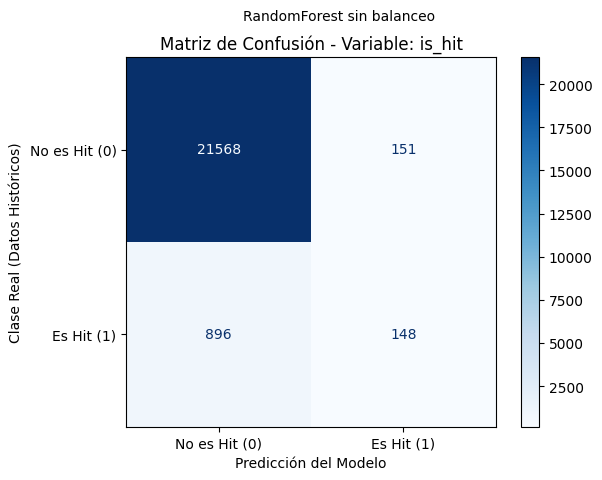

In [11]:
rf = RandomForestClassifier(random_state=42, n_jobs=-1).fit(X_train_c, y_hit_train)
resultados_clf['RandomForest sin balanceo'] = evaluar_clasificador(
    rf, X_test_c, y_hit_test, 'RandomForest sin balanceo', 'matriz_RFC')

Desbalanceo en train: 19.5 No Hit por cada Hit
=== LightGBM con pesos de clase ===
              precision    recall  f1-score   support

      No Hit       0.98      0.88      0.93     21719
         Hit       0.20      0.60      0.30      1044

    accuracy                           0.87     22763
   macro avg       0.59      0.74      0.61     22763
weighted avg       0.94      0.87      0.90     22763



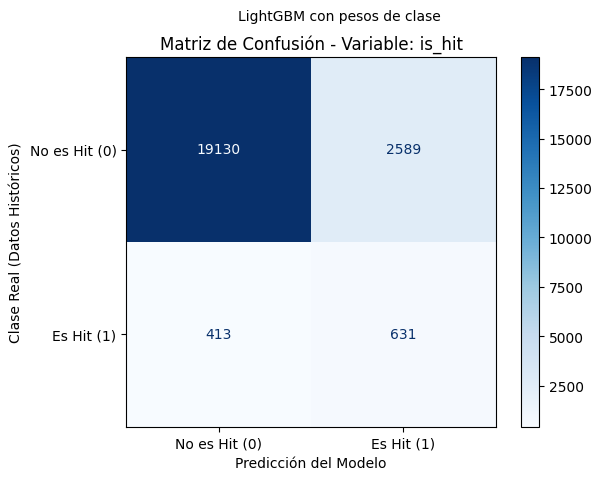

In [12]:
ratio = (y_hit_train == 0).sum() / (y_hit_train == 1).sum()
print(f'Desbalanceo en train: {ratio:.1f} No Hit por cada Hit')

lgbm = LGBMClassifier(scale_pos_weight=ratio, max_depth=6, learning_rate=0.05,
                      random_state=42, n_jobs=-1, verbose=-1).fit(X_train_c, y_hit_train)
resultados_clf['LightGBM con pesos de clase'] = evaluar_clasificador(
    lgbm, X_test_c, y_hit_test, 'LightGBM con pesos de clase', 'matriz1_LGBMC')

### Con sobremuestreo SMOTENC

SMOTENC genera ejemplos sintéticos de la clase minoritaria respetando las variables categóricas (`explicit`, `key`, `mode`, `time_signature` y las columnas binarias del género). Se aplica **solo a train**; el conjunto de prueba conserva la distribución real.

In [13]:
cols_genero = [c for c in X_train_c.columns if c.startswith('track_genre_')]
cols_categoricas = ['explicit', 'key', 'mode', 'time_signature'] + cols_genero

smote_nc = SMOTENC(categorical_features=X_train_c.columns.isin(cols_categoricas).tolist(), random_state=42)
X_train_res, y_train_res = smote_nc.fit_resample(X_train_c, y_hit_train)
print(f'Train tras SMOTENC: {y_train_res.value_counts().to_dict()}')
print(f'Test sin modificar: {y_hit_test.value_counts().to_dict()}')

Train tras SMOTENC: {1: 86362, 0: 86362}
Test sin modificar: {0: 21719, 1: 1044}


=== RandomForest + SMOTENC ===
              precision    recall  f1-score   support

      No Hit       0.97      0.96      0.96     21719
         Hit       0.29      0.37      0.33      1044

    accuracy                           0.93     22763
   macro avg       0.63      0.67      0.65     22763
weighted avg       0.94      0.93      0.93     22763



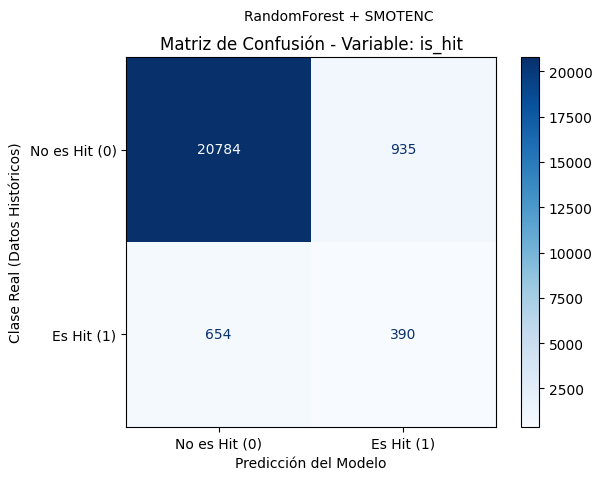

In [14]:
rf_s = RandomForestClassifier(random_state=42, n_jobs=-1).fit(X_train_res, y_train_res)
resultados_clf['RandomForest + SMOTENC'] = evaluar_clasificador(
    rf_s, X_test_c, y_hit_test, 'RandomForest + SMOTENC', 'matriz2_RFC')

=== LightGBM + SMOTENC ===
              precision    recall  f1-score   support

      No Hit       0.98      0.82      0.89     21719
         Hit       0.15      0.67      0.25      1044

    accuracy                           0.81     22763
   macro avg       0.57      0.75      0.57     22763
weighted avg       0.94      0.81      0.86     22763



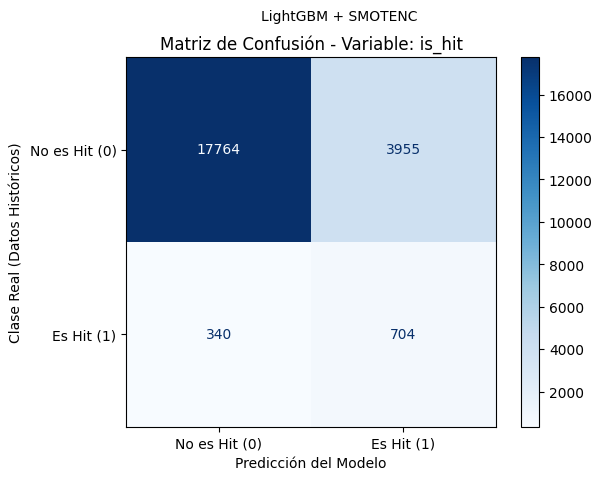

In [15]:
lgbm_s = LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=42,
                        n_jobs=-1, verbose=-1).fit(X_train_res, y_train_res)
resultados_clf['LightGBM + SMOTENC'] = evaluar_clasificador(
    lgbm_s, X_test_c, y_hit_test, 'LightGBM + SMOTENC', 'matriz2_LGBMC')

### Comparación de modelos de clasificación

,precision_hit,recall_hit,f1_hit,roc_auc,pr_auc,hits_detectados,hits_perdidos,falsas_alarmas
RandomForest sin balanceo,0.495,0.142,0.220,0.812,0.268,148.0,896.0,151.0
LightGBM con pesos de clase,0.196,0.604,0.296,0.842,0.312,631.0,413.0,2589.0
RandomForest + SMOTENC,0.294,0.374,0.329,0.826,0.251,390.0,654.0,935.0
LightGBM + SMOTENC,0.151,0.674,0.247,0.815,0.273,704.0,340.0,3955.0


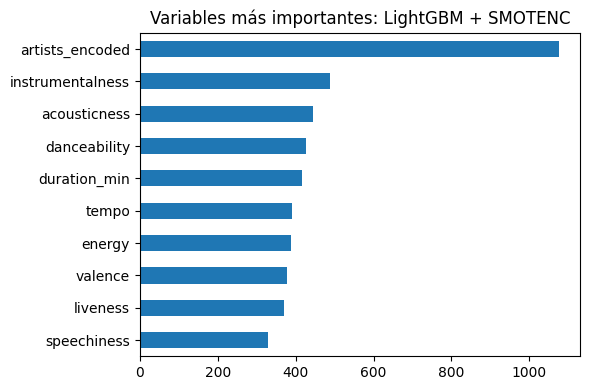

In [16]:
tabla_clf = pd.DataFrame(resultados_clf).T.round(3)
display(tabla_clf)

importancia = pd.Series(lgbm_s.feature_importances_, index=X_train_res.columns).sort_values().tail(10)
importancia.plot.barh(figsize=(6, 4), title='Variables más importantes: LightGBM + SMOTENC')
plt.tight_layout()
plt.savefig(RUTA_IMAGENES / 'importancia_variables.png')
plt.show()

## Modelado supervisado: regresión de popularidad

Se predice `popularity` (0 a 100). Se incluye una **línea base** que predice siempre el promedio de train: un modelo solo es útil si la supera. Se comparan:

* **Ridge:** regresión lineal regularizada, referencia simple e interpretable.
* **RandomForest:** captura relaciones no lineales e interacciones.
* **HistGradientBoosting y XGBoost:** gradient boosting, habitualmente los más precisos en datos tabulares.

In [17]:
X_train_r, X_test_r = preparar(X_train_raw, X_test_raw, y_pop_train, 'continuous')

modelos_reg = {
    'Base (promedio)': DummyRegressor(strategy='mean'),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'RandomForest': RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=600, learning_rate=0.04, max_depth=5,
                            subsample=0.8, colsample_bytree=0.8, random_state=42),
}

resultados_reg, predicciones = {}, {}
for nombre, modelo in modelos_reg.items():
    modelo.fit(X_train_r, y_pop_train)
    pred = modelo.predict(X_test_r)
    predicciones[nombre] = pred
    resultados_reg[nombre] = {'RMSE': np.sqrt(mean_squared_error(y_pop_test, pred)),
                              'MAE': mean_absolute_error(y_pop_test, pred),
                              'R2': r2_score(y_pop_test, pred)}

tabla_reg = pd.DataFrame(resultados_reg).T.round(3)
display(tabla_reg)

,RMSE,MAE,R2
Base (promedio),22.220,18.800,-0.000
Ridge,17.720,13.033,0.364
RandomForest,16.543,11.208,0.446
HistGradientBoosting,16.464,11.253,0.451
XGBoost,16.591,11.386,0.443


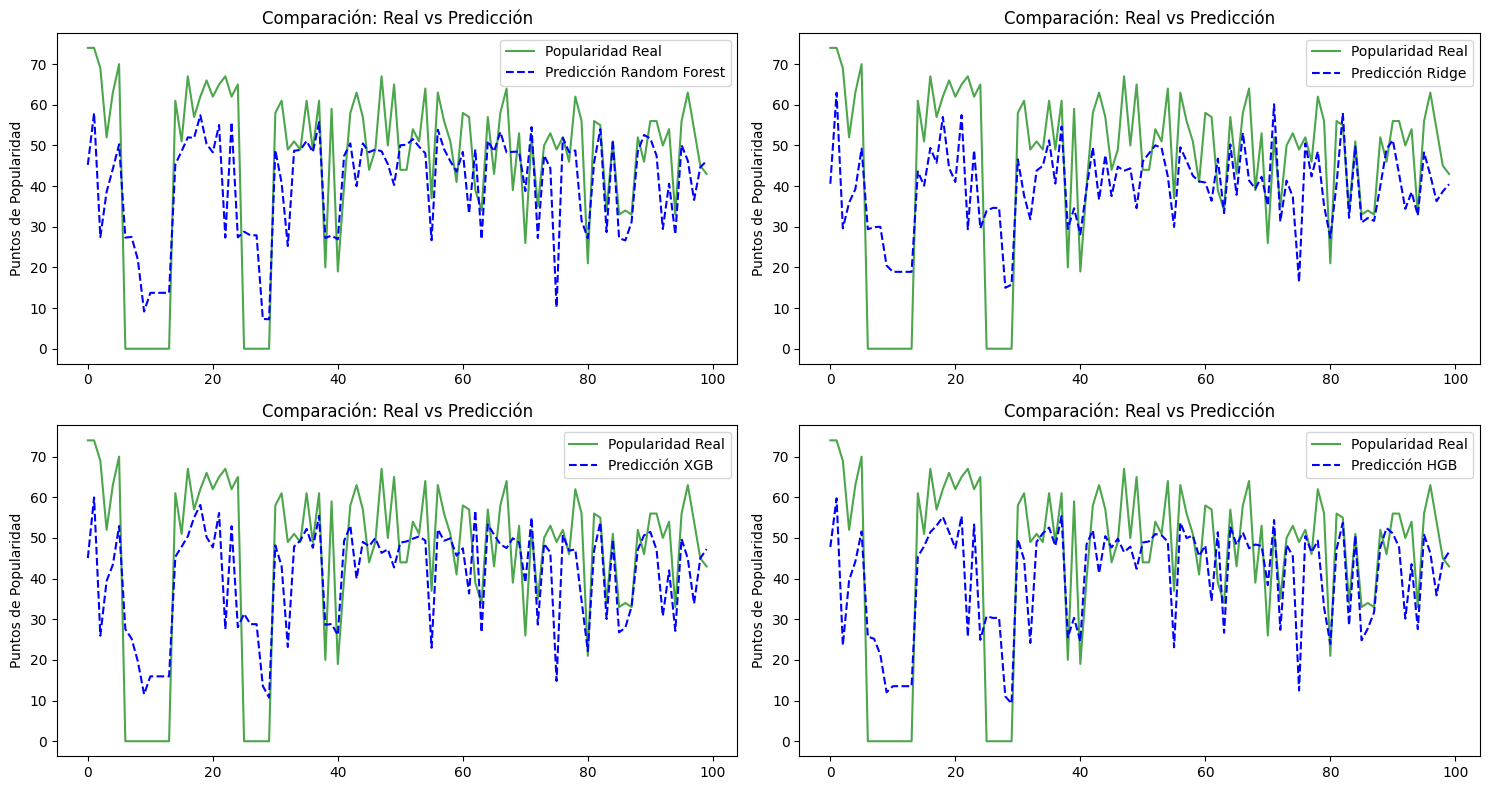

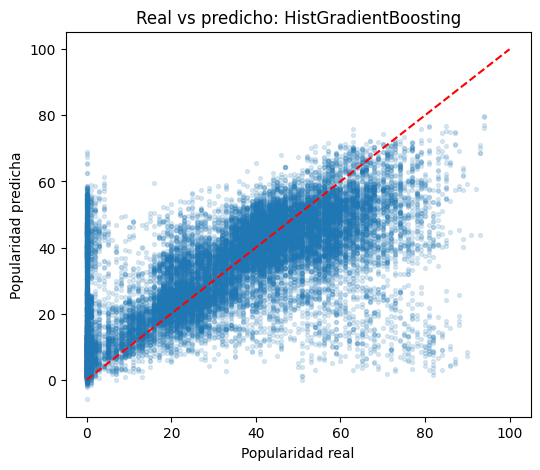

In [18]:
# Figura original (2x2, primeras 100 canciones): mismo nombre de archivo y mismos títulos que antes
fig, axs = plt.subplots(2, 2, figsize=(15, 8))
y_100 = y_pop_test.values[:100]

for ax, (clave, etiqueta) in zip(axs.ravel(), [('RandomForest', 'Random Forest'), ('Ridge', 'Ridge'),
                                                ('XGBoost', 'XGB'), ('HistGradientBoosting', 'HGB')]):
    ax.plot(y_100, label='Popularidad Real', color='green', alpha=0.7)
    ax.plot(predicciones[clave][:100], label=f'Predicción {etiqueta}', color='blue', linestyle='--')
    ax.set_title('Comparación: Real vs Predicción')
    ax.set_ylabel('Puntos de Popularidad')
    ax.legend()

plt.tight_layout()
plt.savefig(RUTA_IMAGENES / 'regresion.png')
plt.show()

# Gráfico adicional (archivo nuevo): real vs predicho del mejor modelo en todo el test
mejor_reg = tabla_reg.drop(index='Base (promedio)')['R2'].idxmax()

plt.figure(figsize=(6, 5))
plt.scatter(y_pop_test, predicciones[mejor_reg], alpha=0.15, s=8)
plt.plot([0, 100], [0, 100], color='red', linestyle='--')
plt.xlabel('Popularidad real')
plt.ylabel('Popularidad predicha')
plt.title(f'Real vs predicho: {mejor_reg}')
plt.savefig(RUTA_IMAGENES / 'regresion_real_vs_predicho.png', bbox_inches='tight')
plt.show()


## Modelado no supervisado: PCA y K-Means

El objetivo es descubrir **perfiles sonoros** de canciones. Se usan solo los nueve atributos de audio, sin `popularity`, `is_hit`, artista ni género, para que los grupos reflejen el sonido y no la variable objetivo. Se trabaja con una fila por canción, ya que una misma canción puede repetirse en varios géneros.

* **PCA:** reduce la correlación entre atributos y permite agrupar en pocas dimensiones. Se retienen los componentes que explican al menos el 80 % de la varianza.
* **K-Means:** agrupa por cercanía a centroides, es simple y escala bien a 90.000 canciones. El número de grupos se elige con el método del codo y el coeficiente de silueta.

5 componentes explican 81.5% de la varianza


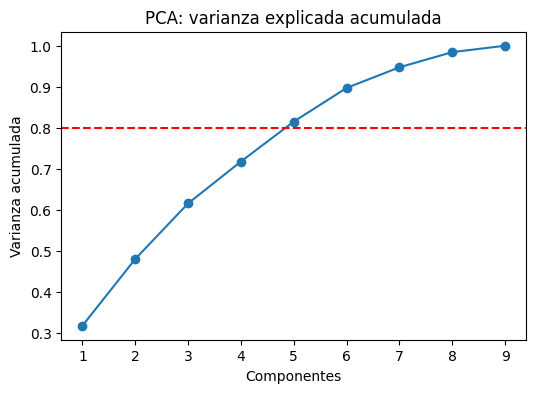

,PC1,PC2,PC3,PC4,PC5
danceability,0.25,0.55,-0.13,0.35,0.18
energy,0.51,-0.28,-0.01,0.15,-0.08
loudness,0.52,-0.07,-0.05,-0.06,-0.20
speechiness,0.12,0.04,0.62,0.40,0.49
acousticness,-0.42,0.34,0.23,-0.29,0.10
instrumentalness,-0.28,-0.33,-0.22,0.54,0.27
liveness,0.10,-0.21,0.69,-0.16,-0.19
valence,0.30,0.52,-0.02,-0.14,0.12
tempo,0.19,-0.27,-0.17,-0.53,0.74


In [19]:
AUDIO = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo']

df_u = df[~grupos.duplicated()].copy()
Z = StandardScaler().fit_transform(df_u[AUDIO])

pca_total = PCA(random_state=42).fit(Z)
var_acum = np.cumsum(pca_total.explained_variance_ratio_)
n_comp = int(np.argmax(var_acum >= 0.80) + 1)
print(f'{n_comp} componentes explican {var_acum[n_comp - 1]:.1%} de la varianza')

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(var_acum) + 1), var_acum, marker='o')
plt.axhline(0.80, color='red', linestyle='--')
plt.xlabel('Componentes')
plt.ylabel('Varianza acumulada')
plt.title('PCA: varianza explicada acumulada')
plt.savefig(RUTA_IMAGENES / 'pca_varianza.png', bbox_inches='tight')
plt.show()

pca = PCA(n_components=n_comp, random_state=42).fit(Z)
Z_pca = pca.transform(Z)
cargas = pd.DataFrame(pca.components_.T, index=AUDIO, columns=[f'PC{i + 1}' for i in range(n_comp)])
display(cargas.round(2))

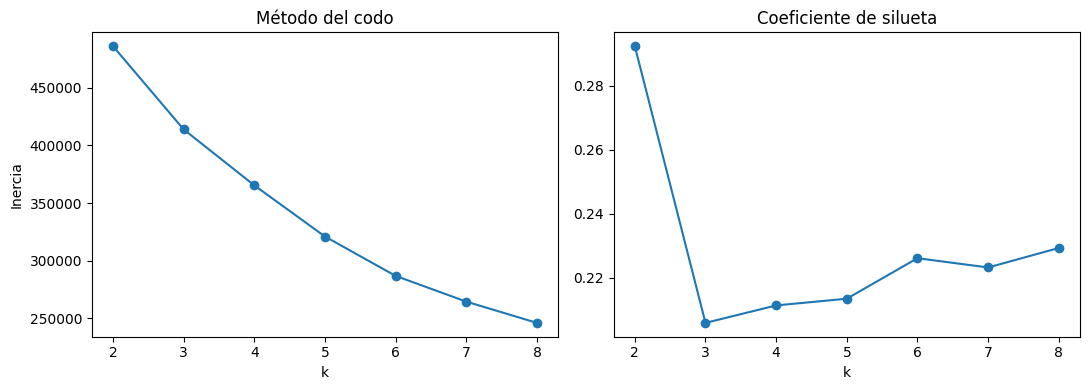

{2: np.float64(0.292), 3: np.float64(0.206), 4: np.float64(0.211), 5: np.float64(0.214), 6: np.float64(0.226), 7: np.float64(0.223), 8: np.float64(0.229)}


In [20]:
rng = np.random.RandomState(42)
muestra = rng.choice(len(Z_pca), 8000, replace=False)

inercias, siluetas = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z_pca)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z_pca[muestra], km.labels_[muestra]))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(ks, inercias, marker='o')
ejes[0].set_title('Método del codo')
ejes[0].set_xlabel('k')
ejes[0].set_ylabel('Inercia')
ejes[1].plot(ks, siluetas, marker='o')
ejes[1].set_title('Coeficiente de silueta')
ejes[1].set_xlabel('k')
plt.tight_layout()
plt.savefig(RUTA_IMAGENES / 'kmeans_k.png', bbox_inches='tight')
plt.show()

print({k: round(s, 3) for k, s in zip(ks, siluetas)})

La silueta es máxima con k = 2, pero ese resultado solo separa canciones suaves de canciones intensas. Se elige **k = 4** por interpretabilidad: el método del codo no muestra un quiebre marcado y la silueta es similar entre k = 3 y k = 8, por lo que se prefiere el número de grupos que entrega perfiles distinguibles y útiles para el negocio. La silueta moderada indica que los grupos se traslapan, algo esperable en un continuo musical.

,canciones,tasa_hit,popularidad_media,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,generos_top
cluster,,,,,,,,,,,,,
0,18667,0.02,30.41,0.44,0.27,-15.32,0.05,0.56,0.26,0.15,0.27,109.92,"sleep, ambient, new-age"
1,36296,0.05,34.62,0.68,0.67,-7.03,0.07,0.23,0.04,0.14,0.65,118.33,"salsa, forro, kids"
2,26523,0.03,32.98,0.48,0.82,-6.04,0.07,0.05,0.19,0.20,0.34,136.87,"black-metal, grindcore, death-metal"
3,8254,0.02,33.94,0.60,0.72,-7.40,0.24,0.29,0.02,0.41,0.55,120.61,"comedy, pagode, sertanejo"


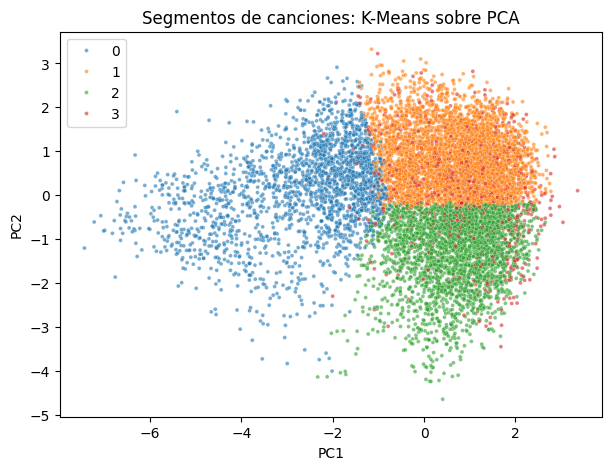

In [21]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z_pca)
df_u['cluster'] = kmeans.labels_

perfil = df_u.groupby('cluster').agg(
    canciones=('is_hit', 'size'),
    tasa_hit=('is_hit', 'mean'),
    popularidad_media=('popularity', 'mean'),
    **{c: (c, 'mean') for c in AUDIO})
perfil['generos_top'] = df_u.groupby('cluster')['track_genre'].agg(
    lambda s: ', '.join(s.value_counts().head(3).index))
display(perfil.round(2))

plt.figure(figsize=(7, 5))
m = rng.choice(len(Z_pca), 10000, replace=False)
sns.scatterplot(x=Z_pca[m, 0], y=Z_pca[m, 1], hue=df_u['cluster'].values[m], palette='tab10', s=8, alpha=0.6)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Segmentos de canciones: K-Means sobre PCA')
plt.savefig(RUTA_IMAGENES / 'clusters_pca.png', bbox_inches='tight')
plt.show()

Los valores de `speechiness`, `acousticness`, `instrumentalness` y `liveness` de la tabla están en escala `log1p`.

**Perfiles encontrados:**

| Grupo | Perfil sonoro | Géneros típicos |
|---|---|---|
| 0 | Suave y acústico: baja energía, volumen bajo, alta acústica | sleep, ambient, new-age |
| 1 | Bailable y positivo: alta danceability y valence | salsa, forró, kids |
| 2 | Intenso: máxima energía, sin componente acústico, tempo alto | black-metal, grindcore, death-metal |
| 3 | Hablado o en vivo: speechiness y liveness altos | comedy, pagode, sertanejo |

La tasa de hits va de 1,6 % (grupo 0) a 5,2 % (grupo 1), frente a 3,5 % en el conjunto de canciones únicas usado aquí (4,8 % si se cuentan las filas repetidas por género). El grupo 1 triplica al grupo 0, pero ningún grupo supera el 6 %: el sonido por sí solo no determina que una canción sea hit.

## Registro de decisiones

| N° | Decisión | Motivo y dato |
|---|---|---|
| 1 | Se eliminan `track_id`, `album_name`, `track_name` y `duration_ms` como variables | Identificador y texto libre sin valor predictivo; `duration_ms` duplica a `duration_min`. |
| 2 | Hit si `popularity >= 70` | Solo 4,8 % de las canciones son hit: clases muy desbalanceadas. |
| 3 | Se mantienen las canciones con `popularity = 0` (14,0 % de las filas) | No se pueden distinguir canciones sin datos de canciones realmente impopulares; se registra como limitación. |
| 4 | Partición agrupada por `track_id` | 23.809 filas repiten `track_id`. Con partición aleatoria, cerca del 31 % de las canciones de test también estaba en train. |
| 5 | Partición estratificada por género | El test contiene los 114 géneros, como pidió el docente. |
| 6 | Codificadores y escalador se ajustan solo con train | Evita que el codificador de artista vea la variable objetivo del test. |
| 7 | Se balancea solo train (SMOTENC) | El test queda con datos reales; datos sintéticos en test invalidarían las métricas. |
| 8 | `log1p` en cinco variables asimétricas y `StandardScaler` en las continuas | `valence` no se escala porque ya está entre 0 y 1. |
| 9 | Métrica principal: matriz de confusión, recall y PR-AUC de Hit | Predecir siempre No Hit da cerca de 95 % de exactitud. |
| 10 | PCA (80 % de varianza) y K-Means solo con atributos de audio, k = 4 | Descubrir perfiles sonoros sin sesgo de la variable objetivo; k = 4 por interpretabilidad. |
| 11 | Limitación: 23 géneros no tienen ningún hit | El modelo no puede aprender hits de esos géneros. |
| 12 | Limitación: el codificador de artista no existe para un artista nuevo | Cerca del 24 % de las canciones de test son de artistas no vistos en train; reciben el promedio global. |
| 13 | Limitación: 1.000 canciones por género | Distribución artificial que no refleja el catálogo real de Spotify. |
| 14 | Se corrige el orden de etiquetas de las matrices de confusión | En la versión anterior las etiquetas `Es Hit` / `No es Hit` estaban invertidas respecto de la matriz. Se conservan nombres de archivo, títulos y ejes. |
| 15 | Resultados más bajos que en la versión anterior | Se eliminó fuga de información (misma canción en train y test, y codificación de artista ajustada con todos los datos). Las métricas anteriores estaban infladas. |


## Interpretación del desempeño

In [22]:
mejor_recall = tabla_clf['recall_hit'].idxmax()
mejor_f1 = tabla_clf['f1_hit'].idxmax()
mejor_pr = tabla_clf['pr_auc'].idxmax()
base_rmse = tabla_reg.loc['Base (promedio)', 'RMSE']
total_hits_test = int(y_hit_test.sum())

print(f"Mayor recall de Hit: {mejor_recall} ({tabla_clf.loc[mejor_recall, 'recall_hit']:.2f})")
print(f"Mayor F1 de Hit: {mejor_f1} ({tabla_clf.loc[mejor_f1, 'f1_hit']:.2f})")
print(f"Mayor PR-AUC: {mejor_pr} ({tabla_clf.loc[mejor_pr, 'pr_auc']:.2f}; referencia aleatoria: {y_hit_test.mean():.2f})")
print(f"Mejor regresor: {mejor_reg} (R2 = {tabla_reg.loc[mejor_reg, 'R2']:.2f}, "
      f"RMSE = {tabla_reg.loc[mejor_reg, 'RMSE']:.1f} frente a {base_rmse:.1f} de la línea base)")

print(f"\nHits reales en test: {total_hits_test}. Qué hace cada modelo con ellos:")
display(tabla_clf[['hits_detectados', 'hits_perdidos', 'falsas_alarmas']].astype(int))


Mayor recall de Hit: LightGBM + SMOTENC (0.67)
Mayor F1 de Hit: RandomForest + SMOTENC (0.33)
Mayor PR-AUC: LightGBM con pesos de clase (0.31; referencia aleatoria: 0.05)
Mejor regresor: HistGradientBoosting (R2 = 0.45, RMSE = 16.5 frente a 22.2 de la línea base)

Hits reales en test: 1044. Qué hace cada modelo con ellos:


,hits_detectados,hits_perdidos,falsas_alarmas
RandomForest sin balanceo,148,896,151
LightGBM con pesos de clase,631,413,2589
RandomForest + SMOTENC,390,654,935
LightGBM + SMOTENC,704,340,3955


**Clasificación.** Sin balanceo, el modelo marca casi todo como No Hit: la exactitud es alta pero el recall de Hit es bajo y se pierden la mayoría de los éxitos. Al ponderar la clase minoritaria o usar SMOTENC aumenta el recall, a costa de precision: aparecen más falsos positivos (canciones marcadas como hit que no lo son).

**Regresión.** El RMSE y el MAE están en puntos de popularidad (0 a 100); el R² indica la proporción de la variación explicada. La referencia es la línea base: la diferencia contra ella mide cuánto aportan realmente los atributos y el artista.

**No supervisado.** Los cuatro perfiles sonoros son claros y coinciden con los géneros, pero ningún perfil supera el 6 % de hits (rango 1,6 % a 5,2 %).

**Recomendaciones para el negocio**

* Usar el modelo de clasificación como **filtro de candidatos** para priorizar canciones que revisar en marketing o listas editoriales, no como decisión automática: con los resultados de la tabla anterior, la precision de Hit va de 0,15 a 0,49: incluso el mejor modelo en precision se equivoca en la mitad de sus alertas, y los demás aciertan en una de cada tres a una de cada siete.
* Elegir el modelo según el costo del error: si perder un hit es más costoso que revisar de más, priorizar recall; si la revisión es costosa, priorizar precision.
* Segmentar playlists y campañas según los perfiles sonoros encontrados, y no esperar que el perfil sonoro por sí solo prediga el éxito: el artista pesa mucho más que cualquier atributo de audio (`artists_encoded` más que duplica a la segunda variable en el gráfico de importancia). El género no aparece entre las diez variables principales, aunque su efecto puede estar repartido en sus siete columnas binarias.
* Usar las predicciones como apoyo técnico y no descartar obras de valor artístico por tener métricas distantes del estándar comercial.
* Para mejorar el desempeño se necesitan variables ausentes del dataset (fecha de lanzamiento, inversión en promoción, presencia en listas).